# 2. Statistical analysis

Notebook 1 showed which groups have more heart disease. This notebook puts numbers on those differences: **how strong** is each association, and **how sure** are we of its size?

## 2.1 Plan, fixed before looking at results

**Family of tests.** One test per predictor against `heart_disease`: 11 categorical and 5 numeric variables, 16 tests in total. Height and weight are left out because BMI is computed from them (notebook 1).

**Hypotheses.** For each predictor:
- H0: the predictor is independent of heart disease (same prevalence in every category, or the same distribution in both outcome groups).
- H1: it is not.

**Significance level.** α = 0.05, family-wise, with a **Holm correction** across the 16 tests.

**Tests.**
- Categorical predictor: Pearson chi-square test of independence.
- Numeric predictor: Mann-Whitney U test. The consumption variables are skewed, discrete and heaped on round numbers (notebook 1), so a rank-based test fits better than a comparison of means.

**What will actually be interpreted: effect sizes.** With about 309,000 respondents the tests can detect differences far too small to matter, so a p-value only says "not exactly zero". The size of each association is reported as:

| Predictor type | Effect size | Reading |
|---|---|---|
| Categorical | Cramér's V (bias-corrected) | 0 = no association, 1 = perfect. Rough guide for a binary outcome: 0.1 small, 0.3 medium, 0.5 large |
| Categorical | Risk ratio and risk difference for one stated contrast, with 95% CI | "x times the prevalence" and "y percentage points more" |
| Numeric | Rank-biserial correlation, with bootstrap 95% CI | P(value is higher with heart disease) − P(lower); 0 = no shift |
| Numeric | Cohen's d, with bootstrap 95% CI | Difference in means in standard deviations; 0.2 small, 0.5 medium, 0.8 large |

**No normality pre-tests.** The original exam notebook used Shapiro-Wilk to choose between tests. At this sample size Shapiro-Wilk rejects for any real variable, so it cannot guide anything. Assumptions are checked here by looking at the data and reasoning about the test.

In [1]:
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import statsmodels.api as sm
from statsmodels.formula.api import ols
from statsmodels.stats.power import TTestIndPower

from cvd import SEED, data, plots, stats
from cvd.data import LABELS, TARGET

plots.set_style()
pd.set_option("display.float_format", "{:,.3f}".format)
pd.set_option("display.width", 200)

ALPHA = 0.05
df = data.load_clean()
print(f"{len(df):,} respondents, {int(df[TARGET].sum()):,} with heart disease ({df[TARGET].mean():.2%})")

308,774 respondents, 24,971 with heart disease (8.09%)


## 2.2 Categorical predictors

Cramér's V summarises the whole table, but it is abstract. So each variable also gets one concrete contrast, chosen in advance: "Yes" against "No" for the binary variables, and the two ends of the scale for the ordinal ones. For checkups the contrast is the most recent category against "5 or more years ago", because "Never" has only 1,407 respondents.

In [2]:
CONTRASTS = {
    "age_category": ("80+", "18-24"),
    "general_health": ("Poor", "Excellent"),
    "diabetes": ("Yes", "No"),
    "arthritis": ("Yes", "No"),
    "smoking_history": ("Yes", "No"),
    "exercise": ("No", "Yes"),
    "sex": ("Male", "Female"),
    "checkup": ("Within the past year", "5 or more years ago"),
    "skin_cancer": ("Yes", "No"),
    "other_cancer": ("Yes", "No"),
    "depression": ("Yes", "No"),
}
cat_table = stats.categorical_association_table(df, CONTRASTS, TARGET).sort_values("cramers_v", ascending=False)

print(f"Smallest expected cell count across all 11 tables: {cat_table['min_expected'].min():.0f}")
cat_table[["levels", "chi2", "dof", "cramers_v"]].assign(p_value=cat_table["p_value"].map(stats.format_p))

Smallest expected cell count across all 11 tables: 114


,levels,chi2,dof,cramers_v,p_value
factor,,,,,
general_health,5,"19,225.978",4,0.250,< 1e-300
age_category,13,"18,033.108",12,0.242,< 1e-300
diabetes,4,"10,413.541",3,0.184,< 1e-300
arthritis,2,"7,312.502",1,0.154,< 1e-300
smoking_history,2,"3,585.338",1,0.108,< 1e-300
exercise,2,"2,864.741",1,0.096,< 1e-300
checkup,5,"2,732.578",4,0.094,< 1e-300
other_cancer,2,"2,634.464",1,0.092,< 1e-300
skin_cancer,2,"2,547.681",1,0.091,< 1e-300


**Assumption check.** The chi-square test needs independent observations and expected counts of at least about 5 per cell. Each row is a different respondent, and the smallest expected count in any cell is 114, so the approximation is safe.

**Result.** Every p-value is astronomically small, which was guaranteed at this sample size and says little. Cramér's V separates the variables properly: self-rated general health and age are in a class of their own, diabetes and arthritis follow, and the rest are weak.

In [3]:
contrast_view = cat_table[["contrast", "prev_reference", "prev_exposed", "risk_ratio", "rr_low", "rr_high", "risk_diff", "rd_low", "rd_high"]]
contrast_view

,contrast,prev_reference,prev_exposed,risk_ratio,rr_low,rr_high,risk_diff,rd_low,rd_high
factor,,,,,,,,,
general_health,Poor vs Excellent,0.020,0.318,15.945,14.956,17.000,0.298,0.289,0.307
age_category,80+ vs 18-24,0.005,0.218,43.311,35.347,53.068,0.213,0.208,0.219
diabetes,Yes vs No,0.061,0.209,3.440,3.357,3.524,0.148,0.144,0.152
arthritis,Yes vs No,0.052,0.141,2.733,2.668,2.799,0.089,0.087,0.092
smoking_history,Yes vs No,0.057,0.116,2.057,2.008,2.107,0.060,0.058,0.062
exercise,No vs Yes,0.067,0.130,1.943,1.896,1.991,0.063,0.060,0.066
checkup,Within the past year vs 5 or more years ago,0.025,0.095,3.712,3.341,4.124,0.069,0.066,0.072
other_cancer,Yes vs No,0.073,0.158,2.173,2.110,2.238,0.085,0.081,0.089
skin_cancer,Yes vs No,0.073,0.156,2.150,2.087,2.214,0.084,0.079,0.088


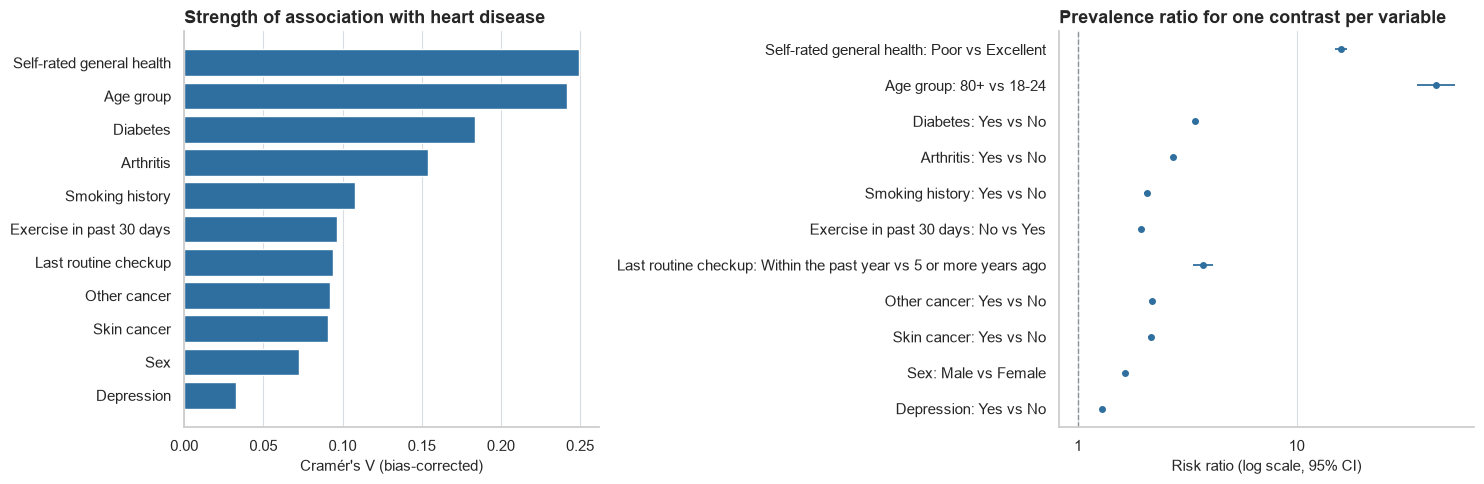

In [4]:
fig, axes = plt.subplots(1, 2, figsize=(15, 5))
plots.horizontal_bar(
    cat_table["cramers_v"].rename(index=LABELS), axes[0], "Strength of association with heart disease", "Cramér's V (bias-corrected)"
)
forest = cat_table.rename(index=lambda c: f"{LABELS[c]}: {CONTRASTS[c][0]} vs {CONTRASTS[c][1]}").rename(
    columns={"rr_low": "ci_low", "rr_high": "ci_high"}
)
plots.forest_plot(forest, axes[1], "Prevalence ratio for one contrast per variable", estimate="risk_ratio", xlabel="Risk ratio (log scale, 95% CI)")
fig.tight_layout()
plots.save_figure(fig, "categorical_effect_sizes")
plt.show()

**Takeaway.**

- **Age:** respondents aged 80+ report heart disease about 43 times as often as those aged 18-24 (21.8% against 0.5%). The interval is wide because heart disease is so rare in the youngest group, but even its lower end is above 35.
- **General health:** "Poor" against "Excellent" is a 16-fold ratio and a gap of 30 percentage points, the largest absolute difference of all.
- **Diabetes, arthritis, cancers, smoking, no exercise:** each goes with two to three and a half times the prevalence (ratios from 1.9 for no exercise to 3.4 for diabetes).
- **Sex and depression:** men have 1.6 times the prevalence of women; depression is the weakest association (ratio about 1.3).
- **Checkup:** a recent checkup goes with almost four times the prevalence. This cannot be a causal effect of seeing a doctor and is discussed as reverse causation in notebook 3.

These are *unadjusted* contrasts. Most of the conditions are much more common in old age, so part of every ratio is age. Notebook 3 separates them.

## 2.3 Numeric predictors

Before testing, a look at what is being compared. The Mann-Whitney test asks whether values in one group tend to be higher than in the other, which is exactly a gap between the two cumulative distribution curves below.

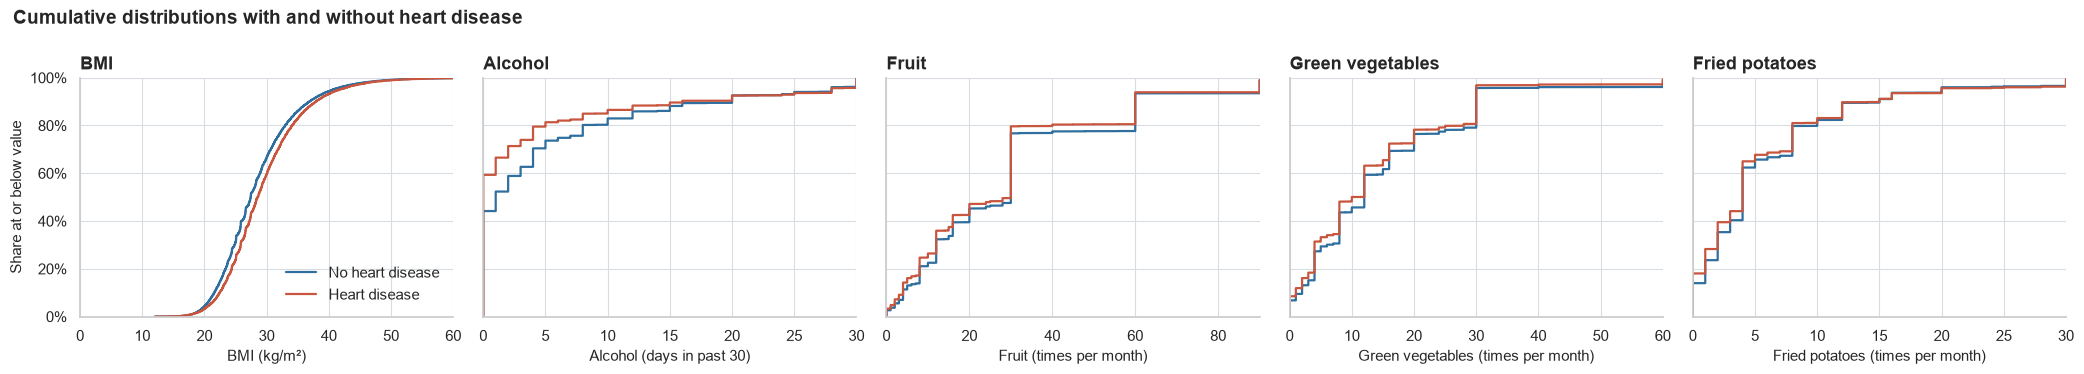

In [5]:
NUMERIC = ["bmi", "alcohol_consumption", "fruit_consumption", "green_vegetables_consumption", "fried_potato_consumption"]
XMAX = {"bmi": 60, "alcohol_consumption": 30, "fruit_consumption": 90, "green_vegetables_consumption": 60, "fried_potato_consumption": 30}

fig, axes = plt.subplots(1, 5, figsize=(21, 3.8), sharey=True)
for ax, col in zip(axes, NUMERIC, strict=True):
    plots.ecdf_by_target(df, col, TARGET, ax, LABELS[col].split(" (")[0], LABELS[col], XMAX[col])
    if col != "bmi":
        ax.set_ylabel("")
axes[0].legend(loc="lower right")
fig.suptitle("Cumulative distributions with and without heart disease", x=0.01, ha="left", fontsize=14, fontweight="bold")
fig.tight_layout()
plt.show()

**Assumption check.** The curves are step functions with large jumps: the variables are discrete and heavily tied, and the alcohol curves start at 44% and 59% because that share of each group reports zero drinking days. A t-test's normality assumption is clearly not met in the raw data, although at this sample size the *means* would still be approximately normal. The Mann-Whitney test only needs independent observations and handles ties through its tie correction, so it is the safer primary test. Cohen's d is reported next to it because it is the more familiar scale.

In every panel the two curves are close together. Whatever the tests say, the distributions overlap almost entirely.

In [6]:
num_table = stats.numeric_association_table(df, NUMERIC, TARGET, n_boot=1000, boot_sample=50_000, seed=SEED)
num_view = num_table.assign(p_value=num_table["p_value"].map(stats.format_p))
num_view[["mean_no_hd", "mean_hd", "median_no_hd", "median_hd", "p_value"]]

,mean_no_hd,mean_hd,median_no_hd,median_hd,p_value
variable,,,,,
bmi,28.544,29.565,27.440,28.550,3.0e-172
alcohol_consumption,5.187,4.085,1.000,0.000,< 1e-300
fruit_consumption,29.982,28.153,30.000,30.000,3.0e-37
green_vegetables_consumption,15.216,13.900,12.000,10.000,4.9e-52
fried_potato_consumption,6.321,6.030,4.000,4.000,1.7e-39


In [7]:
num_view[["rank_biserial", "rb_low", "rb_high", "cohens_d", "d_low", "d_high"]]

,rank_biserial,rb_low,rb_high,cohens_d,d_low,d_high
variable,,,,,,
bmi,0.107,0.097,0.132,0.157,0.132,0.198
alcohol_consumption,-0.152,-0.165,-0.131,-0.134,-0.161,-0.097
fruit_consumption,-0.048,-0.069,-0.033,-0.074,-0.117,-0.054
green_vegetables_consumption,-0.057,-0.076,-0.040,-0.088,-0.110,-0.051
fried_potato_consumption,-0.050,-0.067,-0.029,-0.034,-0.061,0.002


Point estimates use all 308,774 rows. The 95% confidence intervals are percentile bootstrap intervals (1,000 resamples) computed on a seeded random subsample of 50,000 rows to keep the run time down, so they are *wider* than full-data intervals would be, which is the conservative direction. Because the subsample is a different draw, an interval is not always centred on the full-data estimate (BMI is the visible case), but every full-data estimate lies inside its interval.

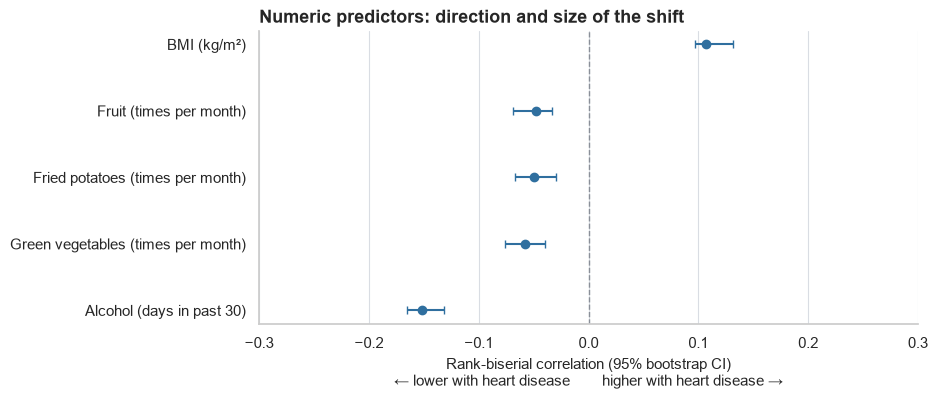

In [8]:
fig, ax = plt.subplots(figsize=(8.5, 3.8))
order = num_table["rank_biserial"].sort_values().index
y = np.arange(len(order))
ax.errorbar(
    num_table.loc[order, "rank_biserial"],
    y,
    xerr=[
        num_table.loc[order, "rank_biserial"] - num_table.loc[order, "rb_low"],
        num_table.loc[order, "rb_high"] - num_table.loc[order, "rank_biserial"],
    ],
    fmt="o",
    color=plots.BLUE,
    capsize=3,
)
ax.axvline(0, color=plots.GREY, linestyle="--", linewidth=1)
ax.set_yticks(y)
ax.set_yticklabels([LABELS[c] for c in order])
ax.set_xlim(-0.3, 0.3)
ax.set_xlabel("Rank-biserial correlation (95% bootstrap CI)\n← lower with heart disease        higher with heart disease →")
ax.set_title("Numeric predictors: direction and size of the shift")
ax.grid(axis="y", visible=False)
plt.show()

**Takeaway.** All five shifts are small.

- **Alcohol** is the largest: respondents with heart disease report *fewer* drinking days (rank-biserial −0.15, Cohen's d −0.13; the median is 0 days against 1). As notebook 1 argued, this most likely reflects age and people cutting down after a diagnosis, not protection.
- **BMI** is higher with heart disease, by about a sixth of a standard deviation (d = 0.16, one BMI point on average).
- **Fruit, green vegetables and fried potatoes** differ by less than 0.1 standard deviations, and the bootstrap interval for the fried potato d touches zero. The fried potato result also has the "wrong" sign (less with heart disease), again because older people eat them less often.

None of these comes close to the associations seen for age or general health.

## 2.4 Multiple testing and why everything is "significant"

In [9]:
family = pd.concat(
    [
        cat_table.assign(test="chi-square", effect=cat_table["cramers_v"], effect_size="Cramér's V")[["test", "p_value", "effect_size", "effect"]],
        num_table.assign(test="Mann-Whitney U", effect=num_table["rank_biserial"], effect_size="rank-biserial r")[["test", "p_value", "effect_size", "effect"]],
    ]
)
family["p_holm"] = stats.holm_adjust(family["p_value"])
family["reject_H0"] = family["p_holm"] < ALPHA
family = family.sort_values("p_value")
print(f"Tests in the family: {len(family)}; H0 rejected after Holm correction: {int(family['reject_H0'].sum())}")
print(f"Largest Holm-adjusted p-value: {family['p_holm'].max():.1e} ({family['p_holm'].idxmax()})")
family.assign(p_value=family["p_value"].map(stats.format_p), p_holm=family["p_holm"].map(stats.format_p))

Tests in the family: 16; H0 rejected after Holm correction: 16
Largest Holm-adjusted p-value: 3.0e-37 (fruit_consumption)


,test,p_value,effect_size,effect,p_holm,reject_H0
general_health,chi-square,< 1e-300,Cramér's V,0.250,< 1e-300,True
age_category,chi-square,< 1e-300,Cramér's V,0.242,< 1e-300,True
diabetes,chi-square,< 1e-300,Cramér's V,0.184,< 1e-300,True
arthritis,chi-square,< 1e-300,Cramér's V,0.154,< 1e-300,True
smoking_history,chi-square,< 1e-300,Cramér's V,0.108,< 1e-300,True
exercise,chi-square,< 1e-300,Cramér's V,0.096,< 1e-300,True
checkup,chi-square,< 1e-300,Cramér's V,0.094,< 1e-300,True
other_cancer,chi-square,< 1e-300,Cramér's V,0.092,< 1e-300,True
skin_cancer,chi-square,< 1e-300,Cramér's V,0.091,< 1e-300,True
sex,chi-square,< 1e-300,Cramér's V,0.073,< 1e-300,True


All 16 null hypotheses are rejected, and the Holm correction changes nothing because the p-values are so far below 0.05. That is not evidence that all 16 variables matter. It is what happens when the sample is this large:

In [10]:
n_hd, n_no = int(df[TARGET].sum()), int((df[TARGET] == 0).sum())
detectable_d = TTestIndPower().solve_power(nobs1=n_hd, ratio=n_no / n_hd, alpha=ALPHA / len(family), power=0.80)
weakest = num_table["cohens_d"].abs().idxmin()
print(f"Group sizes: {n_hd:,} with heart disease, {n_no:,} without")
print(f"Smallest Cohen's d detectable with 80% power at alpha = {ALPHA}/{len(family)}: {detectable_d:.3f}")
print(f"Weakest numeric effect observed: {weakest}, d = {num_table.loc[weakest, 'cohens_d']:.3f}, p = {stats.format_p(num_table.loc[weakest, 'p_value'])}")

Group sizes: 24,971 with heart disease, 283,803 without
Smallest Cohen's d detectable with 80% power at alpha = 0.05/16: 0.025
Weakest numeric effect observed: fried_potato_consumption, d = -0.034, p = 1.7e-39


**Takeaway.** With these group sizes a difference of under 0.03 standard deviations is detected reliably, even after correcting for 16 tests. A difference that small is invisible in practice: the two distributions overlap by about 99%. The weakest effect in this data is larger than that threshold, so it is "highly significant" while being of no practical importance.

The useful ranking is therefore by effect size. From the two tables above:

| Tier | Variables | Evidence |
|---|---|---|
| Strong | General health, age | Cramér's V ≈ 0.25 and 0.24; prevalence differs by a factor of 16 to 44 between the ends of the scale |
| Moderate | Diabetes, arthritis | V ≈ 0.18 and 0.15; prevalence roughly triples |
| Weak | Smoking, exercise, cancers, checkup, sex, alcohol, BMI | V ≈ 0.07 to 0.11, or rank-biserial below 0.2 in absolute value |
| Negligible | Depression, fruit, green vegetables, fried potatoes | V ≈ 0.03; rank-biserial below 0.06 in absolute value |

All of this is unadjusted. The next notebook asks which associations survive once age, sex and the other variables are held fixed.

---
## 2.5 Sidebar: a lesson in confounding

This section is a short detour, kept from the original exam project because it is a clean demonstration of how a real, highly significant difference can be entirely misleading.

**The question:** are people with a smoking history taller?

In [11]:
smokers = df.loc[df["smoking_history"] == "Yes", "height_cm"]
non_smokers = df.loc[df["smoking_history"] == "No", "height_cm"]
marginal = stats.mean_difference_ci(smokers, non_smokers)
print(f"Mean height, smoking history: {smokers.mean():.2f} cm   no history: {non_smokers.mean():.2f} cm")
print(f"Difference: {marginal['mean_diff']:.2f} cm (95% CI {marginal['ci_low']:.2f} to {marginal['ci_high']:.2f}), Welch t-test p = {stats.format_p(marginal['p_value'])}")
print(f"Cohen's d = {marginal['cohens_d']:.3f}")

Mean height, smoking history: 171.28 cm   no history: 170.16 cm
Difference: 1.12 cm (95% CI 1.05 to 1.20), Welch t-test p = 1.4e-183
Cohen's d = 0.106


Taken at face value: yes. Smokers are about 1.1 cm taller, the confidence interval is narrow and far from zero, and the p-value is minuscule. A Welch t-test is appropriate here: height within each group is close to symmetric and bell-shaped, and with over 100,000 people per group the sampling distribution of the mean is normal regardless.

But smoking does not make anyone taller. Something else differs between the two groups.

In [12]:
by_sex = df.groupby("sex", observed=True).agg(
    n=("height_cm", "size"), mean_height=("height_cm", "mean"), smoking_rate=("smoking_history", lambda s: (s == "Yes").mean())
)
print(by_sex.round(3), "\n")
print("Standard deviation of height in each sex x smoking cell:")
print(df.groupby(["sex", "smoking_history"], observed=True)["height_cm"].std().round(2).to_string(), "\n")

stratified = pd.DataFrame(
    {
        sex: stats.mean_difference_ci(
            df.loc[(df["sex"] == sex) & (df["smoking_history"] == "Yes"), "height_cm"],
            df.loc[(df["sex"] == sex) & (df["smoking_history"] == "No"), "height_cm"],
        )
        for sex in ["Female", "Male"]
    }
).T
stratified["p_value"] = stratified["p_value"].map(stats.format_p)
print("Smokers minus non-smokers, within each sex:")
stratified

             n  mean_height  smoking_rate
sex                                      
Female  160155      163.447         0.371
Male    148619      178.340         0.443 

Standard deviation of height in each sex x smoking cell:
sex     smoking_history
Female  No                7.530
        Yes               7.350
Male    No                7.880
        Yes               7.720 

Smokers minus non-smokers, within each sex:


,mean_diff,ci_low,ci_high,p_value,cohens_d
Female,0.213,0.138,0.289,2.7e-08,0.029
Male,-0.195,-0.275,-0.115,1.7e-06,-0.025


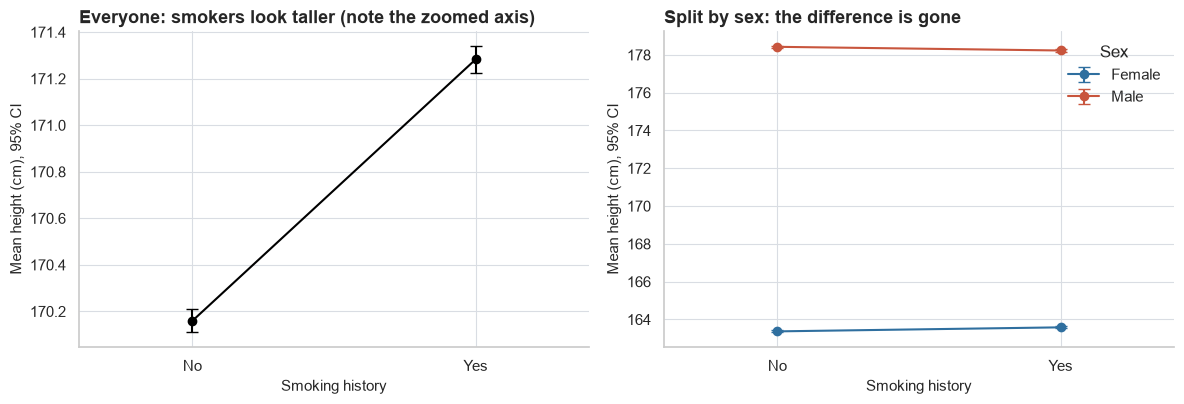

In [13]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4.2))
plots.group_means(df, "height_cm", "smoking_history", axes[0], "Everyone: smokers look taller (note the zoomed axis)", "Mean height (cm), 95% CI")
axes[0].set_xlabel("Smoking history")
plots.group_means(df, "height_cm", "smoking_history", axes[1], "Split by sex: the difference is gone", "Mean height (cm), 95% CI", hue="sex")
axes[1].set_xlabel("Smoking history")
fig.tight_layout()
plots.save_figure(fig, "confounding_height_smoking")
plt.show()

Men are about 15 cm taller than women, and men are more likely to have a smoking history (44% against 37%). The "smokers" group therefore contains more men, and that alone makes it taller on average. Within each sex the difference is about 0.2 cm (Cohen's d below 0.03) and points in opposite directions for men and women. Those within-sex differences still have p-values below 0.00001, which is one more reminder of what this sample size does to p-values.

A two-way ANOVA says the same thing in one model, with partial η² as the share of variance each term explains after the others:

In [14]:
anova_model = ols("height_cm ~ C(smoking_history) * C(sex)", data=df).fit()
anova = sm.stats.anova_lm(anova_model, typ=2)
anova_view = anova.drop(index="Residual").assign(partial_eta_sq=stats.partial_eta_squared(anova))
anova_view["PR(>F)"] = anova_view["PR(>F)"].map(stats.format_p)
anova_view.index = ["Smoking history", "Sex", "Smoking × sex"]
print(f"Model R² = {anova_model.rsquared:.3f}")
pd.set_option("display.float_format", "{:,.6f}".format)
anova_view[["df", "F", "PR(>F)", "partial_eta_sq"]]

Model R² = 0.487


,df,F,PR(>F),partial_eta_sq
Smoking history,1.000000,0.160396,0.689,0.000001
Sex,1.000000,"292,009.142712",< 1e-300,0.486051
Smoking × sex,1.000000,52.964868,3.4e-13,0.000172


**Assumptions, by reasoning rather than by pre-test.** ANOVA assumes independent observations, roughly equal variances and roughly normal residuals. The four sex × smoking cells have similar standard deviations (printed above), and with tens of thousands of respondents per cell the F-test is robust to the mild non-normality that heights rounded to whole centimetres produce.

**Takeaway.**

- **Sex** explains almost half the variance in height (partial η² ≈ 0.49).
- **Smoking**, once sex is in the model, explains essentially none (partial η² under one millionth, p = 0.69).
- The **interaction** is "significant" (p ≈ 3 × 10⁻¹³) with a partial η² of 0.0002. This is the lesson of section 2.4 again: at n = 308,774, significance without an effect size means nothing.

**Why this belongs in a heart disease project.** The same mechanism runs through the main analysis. Smokers, diabetics and non-drinkers differ from everyone else in age and sex, and age is the strongest predictor of heart disease in this data. The unadjusted ratios in section 2.2 are to those variables what the 1.1 cm is to smoking and height: real differences between groups, but not the effect of the label on the group. Notebook 3 adjusts for this.

## Summary

- All 16 predictors are associated with heart disease at the Holm-corrected 5% level. With 308,774 respondents this was inevitable and is not informative.
- By effect size, **self-rated general health** and **age** are the strong associations, **diabetes** and **arthritis** moderate, and the lifestyle variables weak. The diet variables are negligible.
- Several raw associations point in implausible directions (less alcohol and fewer fried potatoes with heart disease, recent checkups with more), which signals confounding by age and reverse causation.
- The confounding sidebar shows how a difference of 1.1 cm with a p-value below 10⁻¹⁰⁰ disappears when the right variable is controlled for.

Next: [notebook 3](03_logistic_regression.ipynb) estimates adjusted associations with logistic regression.